# Интерпретация sequence2function-моделей на примере lentiMPRA


## Биологический контекст: что измеряет Agarwal lentiMPRA

В lentiMPRA тысячи 200-нуклеотидных регуляторных фрагментов встраиваются в lentiviral reporter-конструкции. Для каждого фрагмента связываются баркоды, затем секвенируются:

- **DNA barcode counts** — сколько конструкций присутствует;
- **RNA barcode counts** — сколько reporter-транскрипта произведено.

Активность элемента приблизительно определяется как:

$activity = \log_2(\text{RNA counts}/\text{DNA counts})$

В совместном Agarwal-наборе один и тот же фрагмент оценивался в трёх контекстах:

- **HepG2** — печёночно-подобная клеточная линия;
- **K562** — лейкозная клеточная линия с эритроидными особенностями;
- **WTC11** — линия индуцированных плюрипотентных клеток.

Это не измерение экспрессии гена в его естественном локусе: reporter находится в случайных местах интеграции, а исходные enhancer–promoter контакты и локальная 3D-хроматиновая среда не сохраняются полностью.

In [ ]:
# Схема пайплайна. Вся отрисовка вынесена в модуль tutorial_plotting.py.
# Сначала ищем корень клонированного репозитория; Google Drive подключается
# только если локальная копия проекта не найдена.
import sys
from pathlib import Path

_pkg_candidates = [
    Path.cwd(),
    Path.cwd() / 'sirius_tutorial',
    Path('/content/sirius2026'),
    Path('/content/sirius_tutorial'),
]
_pkg_root = next((p for p in _pkg_candidates if (p / 'tutorial_plotting.py').exists()), None)

if _pkg_root is None:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        _drive_candidates = [
            Path('/content/drive/MyDrive/sirius2026'),
            Path('/content/drive/MyDrive/sirius_tutorial'),
        ]
        _pkg_root = next((p for p in _drive_candidates if (p / 'tutorial_plotting.py').exists()), None)
    except ImportError:
        pass

if _pkg_root is None:
    raise FileNotFoundError(
        'Cannot find the project root. Run the notebook from the cloned repository '
        'or place it at /content/sirius2026.'
    )
sys.path.insert(0, str(_pkg_root))

from tutorial_plotting import draw_pipeline_schematic

draw_pipeline_schematic()

## Что такое sequence2function-модель

Пусть `s` — DNA-последовательность. Модель аппроксимирует функцию:


$f_\theta(s) = (y_{HepG2}, y_{K562}, y_{WTC11})$

Модель предсказатель получает one-hot представление последовательности и извлекает локальные и более длинные комбинации сигналов с помощью свёрточных блоков. В конце общие признаки поступают в голову с тремя регрессионными выходами.

Значение `predicted_*` — это прогноз модели. Значение `queried_*` в файлах генерации — **целевой профиль, который был запрошен у генератора**.

## Attribution: что именно мы хотим объяснить

**Attribution** — это способ сопоставить предсказание модели с входом: каждому основанию или позиции приписывается число, отражающее её влияние на выбранную целевую функцию.

Для модели на основе последовательности важно заранее выбрать, какой эффект мы хотим предсказывать:

- `activity HepG2` — абсолютный прогноз в HepG2;
- `activity K562` — абсолютный прогноз в K562;
- `HepG2 − K562` — клеточный контраст;
- `MinGap HepG2 = HepG2 − max(K562, WTC11)` — активность в таргетной клеточной линии относительно остальных

Одна и та же последовательность может иметь разные карты attribution для разных таргетов.

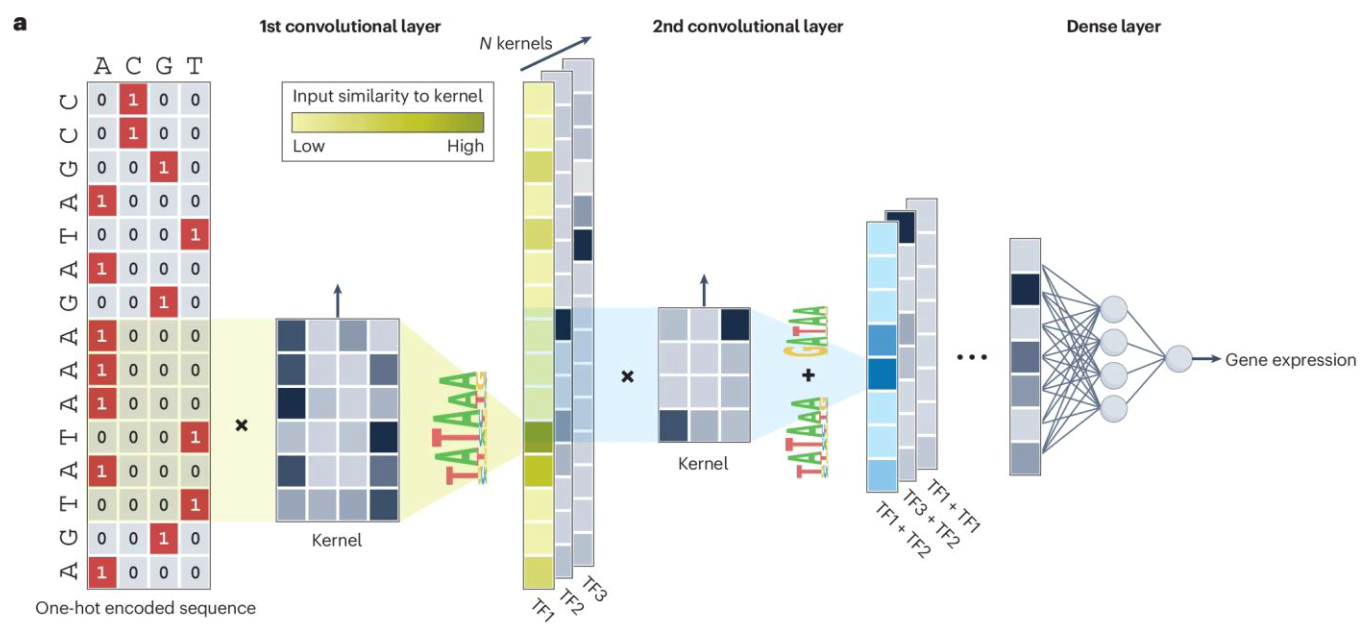

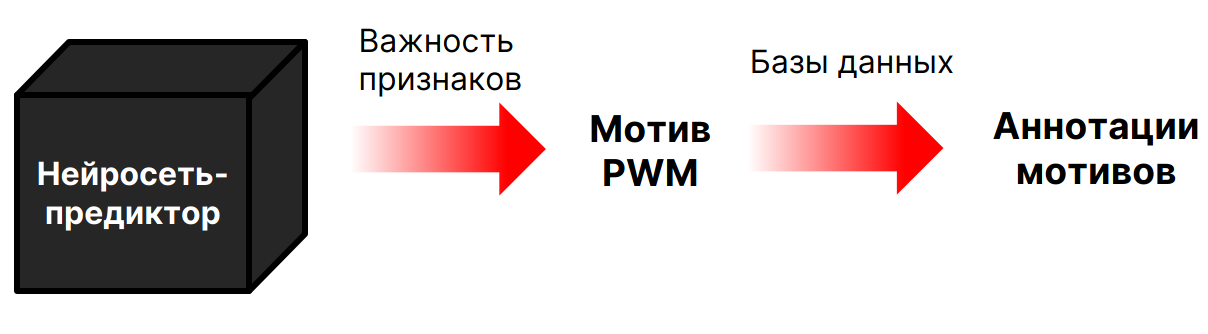

## ISM: In-silico saturation mutagenesis

In-silico saturation mutagenesis (ISM) перебирает все одиночные замены:


$\Delta_{i,b} = f(s_{i\leftarrow b}) - f(s)$

где `i` — позиция, а `b` — один из A/C/G/T.

В Tangermeme для каждой позиции также центрируют эффекты относительно среднего по четырём основаниям. Получается **hypothetical attribution** размерности `4 × L`: что сказала бы модель, если в позиции стояла каждая из букв.

Умножение на исходный one-hot и суммирование по алфавиту даёт **projected attribution** — сигнал для реально присутствующего основания.

**Почему ISM полезен:** он не требует градиентов, непосредственно связан с дискретной мутацией и легко объясняется биологам. **Ограничение:** это локальный анализ одиночных замен; эпистаз и совместные мутации напрямую не измеряются.

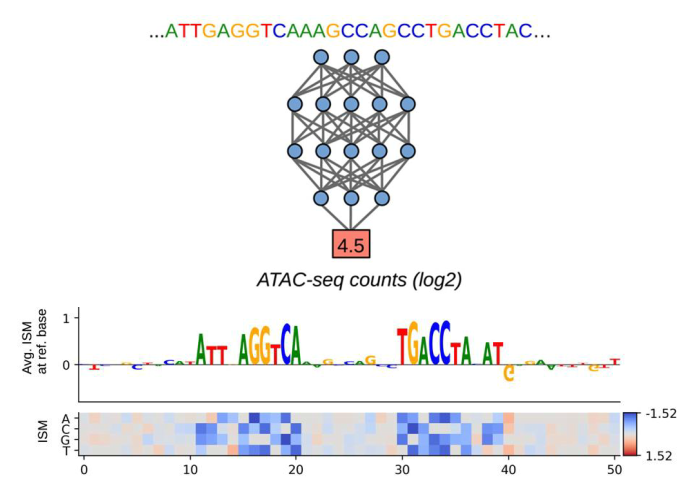

## Техническая оговорка про assay-конструкцию

Checkpoint обучен на входе длины 230 nt:

```text
15 nt constant assay flank + 200 nt insert + 15 nt constant assay flank
```

В ноутбуке модель всегда получает полный 230-nt input, но ISM запускается только для центральных 200 nt. Фланки остаются неизменными и не интерпретируются как найденные биологические мотивы.

In [ ]:
# Основные импорты. Для установки зависимостей из корня репозитория:
# !python -m pip install -r requirements.txt

from pathlib import Path
import importlib.util
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display, HTML, clear_output

from tangermeme.saturation_mutagenesis import saturation_mutagenesis
from tangermeme.seqlet import recursive_seqlets
from tangermeme.annotate import annotate_seqlets, read_meme

# Используем второй GPU на сервере, если он есть; в Colab/обычной машине — первый.
if torch.cuda.is_available():
    DEVICE = 'cuda:1' if torch.cuda.device_count() > 1 else 'cuda:0'
else:
    DEVICE = 'cpu'
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.startswith('cuda'):
    print('GPU:', torch.cuda.get_device_name(torch.device(DEVICE)))

BASES = 'ACGT'
BASE_TO_INDEX = {b: i for i, b in enumerate(BASES)}
ONEHOT = np.eye(4, dtype=np.float32)

In [ ]:
DEVICE

In [ ]:
# Пути к данным. В приоритете корень клонированного репозитория.
# Для Colab допустимы /content, Google Drive и ручная загрузка assets.

REMOTE_FRAMEWORKS = Path('/home/ak_ryb/ml_projects/parade_star/generated/agarwal/frameworks')
REMOTE_WEIGHTS = Path('/home/kekulen/ml_projects/parade_star/models-weights/predictors/agarwal/epoch042-r0.79896.ckpt')
REMOTE_MEME = Path('/home/kekulen/ml_projects/parade_star/data/motifs/hocomoco_v14/H14CORE-CLUSTERED_meme_format.meme')
PORTABLE_ROOTS = [
    Path.cwd(),
    Path('/content/sirius2026'),
    Path('/content/sirius_tutorial'),
    Path('/content/drive/MyDrive/sirius2026'),
    Path('/content/drive/MyDrive/sirius_tutorial'),
    Path('/home/kekulen/ml_projects/parade_star/sirius_tutorial'),
    Path.cwd() / 'sirius_tutorial',
]
PORTABLE_ROOT = next(
    (p for p in PORTABLE_ROOTS
     if (p / 'models').exists() and (p / 'frameworks').exists() and (p / 'motifs').exists()),
    None,
)
if PORTABLE_ROOT is not None:
    FRAMEWORK_DIR = PORTABLE_ROOT / 'frameworks'
    WEIGHTS_PATH = PORTABLE_ROOT / 'models' / 'epoch042-r0.79896.ckpt'
    MEME_PATH = PORTABLE_ROOT / 'motifs' / 'H14CORE-CLUSTERED_meme_format.meme'
else:
    FRAMEWORK_DIR = REMOTE_FRAMEWORKS
    WEIGHTS_PATH = REMOTE_WEIGHTS
    MEME_PATH = REMOTE_MEME

print('Tutorial assets:', PORTABLE_ROOT or 'repository paths')
print('Framework directory:', FRAMEWORK_DIR)
print('Weights:', WEIGHTS_PATH)
print('Motif database:', MEME_PATH)
if not FRAMEWORK_DIR.exists() or not WEIGHTS_PATH.exists() or not MEME_PATH.exists():
    raise FileNotFoundError(
        'Tutorial assets are missing. Run from the repository root or check the asset layout.'
    )

In [ ]:
# Используем bundled LegNet architecture, чтобы после git clone не требовался
# отдельный пакет mpramnist. Внешний mpramnist остаётся допустимым fallback.
_model_sources = []
if PORTABLE_ROOT is not None:
    _model_sources.append(PORTABLE_ROOT / 'vendor' / 'mpramnist' / 'models' / 'MPRALegNet.py')
try:
    import mpramnist
    _model_sources.append(Path(mpramnist.__file__).resolve().parent / 'models' / 'MPRALegNet.py')
except ImportError:
    pass
model_source = next((p for p in _model_sources if p.exists()), None)
if model_source is None:
    raise FileNotFoundError('Cannot find bundled or installed MPRALegNet.py')
spec = importlib.util.spec_from_file_location('mpramnist_legnet_source', model_source)
legnet_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(legnet_module)

checkpoint = torch.load(WEIGHTS_PATH, map_location='cpu', weights_only=False)

hparams = checkpoint['hyper_parameters']
CELL_TYPES = list(hparams['celltypes'])
model_config = dict(hparams['model_config'])
model_config.pop('left_flank', None)
model_config.pop('right_flank', None)
net = legnet_module.HumanLegNet(in_ch=4, output_dim=len(CELL_TYPES), **model_config)
net.load_state_dict({k[len('model.'):]: v for k, v in checkpoint['state_dict'].items() if k.startswith('model.')})
net = net.to(DEVICE).eval()

state = checkpoint['state_dict']
def decode_onehot_tensor(x):
    x = x.detach().cpu().numpy()
    if x.ndim == 3: x = x[0]
    return ''.join(BASES[i] for i in x.argmax(axis=0))

ASSAY_LEFT = decode_onehot_tensor(state['left_flank']) if 'left_flank' in state else 'AGGACCGGATCAACT'
ASSAY_RIGHT = decode_onehot_tensor(state['right_flank']) if 'right_flank' in state else 'CATTGCGTGAACCGA'

print('Cell types:', CELL_TYPES)
print('Architecture:', model_config)
print('Model source:', model_source)
print('Assay flanks:', ASSAY_LEFT, ASSAY_RIGHT)
print('Checkpoint epoch:', checkpoint.get('epoch'))

In [ ]:
def encode_core(sequences):
    sequences = [str(s).upper() for s in sequences]
    if any(len(s) != 200 for s in sequences):
        bad = [(i, len(s)) for i, s in enumerate(sequences) if len(s) != 200][:5]
        raise ValueError(f'Expected 200-nt inserts; examples of bad lengths: {bad}')
    return torch.tensor(np.stack([ONEHOT[[BASE_TO_INDEX[b] for b in s]].T for s in sequences]), dtype=torch.float32)

def add_assay_flanks(x_core):
    left = torch.tensor(ONEHOT[[BASE_TO_INDEX[b] for b in ASSAY_LEFT]].T, dtype=torch.float32)
    right = torch.tensor(ONEHOT[[BASE_TO_INDEX[b] for b in ASSAY_RIGHT]].T, dtype=torch.float32)
    return torch.cat([left.expand(len(x_core), -1, -1), x_core, right.expand(len(x_core), -1, -1)], dim=2)

@torch.inference_mode()
def predict_sequences(sequences, batch_size=4):
    outputs = []
    for start in range(0, len(sequences), batch_size):
        x_core = encode_core(sequences[start:start+batch_size])
        x = add_assay_flanks(x_core).to(DEVICE)
        y_forward = net(x)
        y_reverse = net(x.flip((1, 2)))
        outputs.append(((y_forward + y_reverse) / 2).detach().cpu())
    return torch.cat(outputs).numpy()

# Smoke test: one real sequence.
if FRAMEWORK_DIR.exists():
    smoke_file = sorted(FRAMEWORK_DIR.glob('*.tsv'))[0]
    smoke_seq = pd.read_csv(smoke_file, sep='\t', nrows=1).loc[0, 'sequence']
    print('Smoke prediction:', dict(zip(CELL_TYPES, np.round(predict_sequences([smoke_seq])[0], 3))))

## Загружаем готовые дизайны и выбираем контрастные примеры

В каждом TSV находятся 1024 последовательности. Для лекции используем два заранее выбранных примера:

- `mdlm_gamma0.tsv`, строка 862 — сильный HepG2-specific прогноз;
- `permutator_gamma0.tsv`, строка 393 — сильный K562-specific прогноз.

Это не утверждение, что такие последовательности уже экспериментально валидированы. Это хорошие объекты для демонстрации того, как модель формирует гипотезу и насколько эта гипотеза объяснима.

In [ ]:
framework_files = sorted(FRAMEWORK_DIR.glob('*.tsv')) if FRAMEWORK_DIR.exists() else []
all_rows = []
for path in framework_files:
    d = pd.read_csv(path, sep='\t')
    pred_cols = [f'predicted_{ct}' for ct in CELL_TYPES]
    query_cols = [f'queried_{ct}' for ct in CELL_TYPES]
    pred = d[pred_cols].to_numpy()
    order = np.argsort(pred, axis=1)[:, ::-1]
    sorted_pred = np.take_along_axis(pred, order, axis=1)
    d['framework'] = path.stem
    d['row'] = np.arange(len(d))
    d['dominant_cell'] = [CELL_TYPES[i] for i in order[:, 0]]
    d['min_gap'] = sorted_pred[:, 0] - sorted_pred[:, 1]
    d['gc_fraction'] = d['sequence'].map(lambda s: (s.count('G') + s.count('C')) / len(s))
    d['prediction_error'] = np.abs(d[pred_cols].to_numpy() - d[query_cols].to_numpy()).mean(axis=1)
    all_rows.append(d)
summary_df = pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame()
print('Loaded files:', [p.name for p in framework_files])
print('Total sequences:', len(summary_df))
if len(summary_df):
    display(summary_df.groupby(['framework', 'dominant_cell']).size().unstack(fill_value=0))

In [ ]:
EXAMPLES = {
    'HepG2-specific / MDLM gamma0': ('mdlm_gamma0.tsv', 862, 'HepG2'),
    'K562-specific / permutator gamma0': ('permutator_gamma0.tsv', 393, 'K562'),
    'K562-specific / MDLM gamma1': ('mdlm_gamma1.tsv', 459, 'K562'),
    'WTC11-specific / MDLM gamma0': ('mdlm_gamma0.tsv', 367, 'WTC11'),
    'K562-specific / MDLM gamma0 row 649': ('mdlm_gamma0.tsv', 649, 'K562'),
}

def load_example(label):
    filename, row, target = EXAMPLES[label]
    path = FRAMEWORK_DIR / filename
    d = pd.read_csv(path, sep='\t')
    record = d.loc[row].to_dict()
    record.update(example=label, source_file=filename, source_row=row, target=target)
    return record

example_records = [load_example(label) for label in EXAMPLES]
example_table = pd.DataFrame(example_records)
cols = ['example', 'source_file', 'source_row', 'target']
for ct in CELL_TYPES:
    cols += [f'queried_{ct}', f'predicted_{ct}']
display(example_table[cols].round(3))

## Fitness-функции для attribution

Внутри модели три выхода. Чтобы получить одну карту ISM, выбираем скалярную fitness-функцию. Это важный ML-момент: attribution относится не просто к последовательности, а к паре **(последовательность, target function)**.

In [ ]:
FITNESS_NAMES = [
    'activity HepG2', 'activity K562', 'activity WTC11',
    'HepG2 - K562', 'K562 - HepG2',
    'MinGap HepG2', 'MinGap K562', 'MinGap WTC11',
]

def fitness_from_predictions(pred, name):
    # pred shape: (batch, 3), columns follow CELL_TYPES.
    i = {ct: k for k, ct in enumerate(CELL_TYPES)}
    if name.startswith('activity '):
        return pred[:, i[name.split()[-1]]]
    if name == 'HepG2 - K562': return pred[:, i['HepG2']] - pred[:, i['K562']]
    if name == 'K562 - HepG2': return pred[:, i['K562']] - pred[:, i['HepG2']]
    target = name.split()[-1]
    j = i[target]
    other = np.delete(pred, j, axis=1).max(axis=1)
    return pred[:, j] - other

class FitnessHead(nn.Module):
    def __init__(self, name):
        super().__init__(); self.name = name
    def forward(self, x):
        x = x.float()
        y = (net(x) + net(x.flip((1, 2)))) / 2
        i = {ct: k for k, ct in enumerate(CELL_TYPES)}
        if self.name.startswith('activity '):
            return y[:, i[self.name.split()[-1]]:i[self.name.split()[-1]]+1]
        if self.name == 'HepG2 - K562': return (y[:, i['HepG2']] - y[:, i['K562']]).unsqueeze(1)
        if self.name == 'K562 - HepG2': return (y[:, i['K562']] - y[:, i['HepG2']]).unsqueeze(1)
        target = self.name.split()[-1]; j = i[target]
        other = torch.cat([y[:, :j], y[:, j+1:]], dim=1).max(dim=1).values
        return (y[:, j] - other).unsqueeze(1)

## Запускаем ISM только на центральной вставке

Tangermeme вернёт hypothetical attribution для всех четырёх оснований в каждой из 200 позиций. Один запуск для одной последовательности и одного fitness — это примерно `200 × 4` однонуклеотидных вариантов, каждый из которых проходит через предсказатель.

In [ ]:
ISM_CACHE = {}

def run_ism(sequence, fitness_name, batch_size=32):
    key = (sequence, fitness_name)
    if key in ISM_CACHE:
        return ISM_CACHE[key]
    x_full = add_assay_flanks(encode_core([sequence])).to(DEVICE)
    head = FitnessHead(fitness_name).to(DEVICE).eval()
    attr = saturation_mutagenesis(
        head, x_full, start=15, end=215, batch_size=batch_size,
        hypothetical=True, device=DEVICE, verbose=False
    )
    attr = attr.detach().cpu().numpy()[0]  # (4, 200)
    observed_attr = saturation_mutagenesis(
        head, x_full, start=15, end=215, batch_size=batch_size,
        hypothetical=False, device=DEVICE, verbose=False
    )
    observed_attr = observed_attr.detach().cpu().numpy()[0]  # (4, 200)
    ism_track = observed_attr.sum(axis=0)
    x_core = encode_core([sequence]).numpy()[0]
    projected = ism_track
    seqlets = recursive_seqlets(
        projected[None], threshold=0.05, min_seqlet_len=5,
        max_seqlet_len=25, additional_flanks=1
    )
    seqlets = seqlets[seqlets['attribution'] >= 0.2].head(8).reset_index(drop=True)
    result = {
        'attr': attr, 'observed_attr': observed_attr,
        'projected': projected, 'ism_track': ism_track, 'seqlets': seqlets,
    }
    ISM_CACHE[key] = result
    return result

print('ISM function ready. First interactive run may take a few seconds on GPU.')

In [ ]:
# Motif database: use the clustered HOCOMOCO v14 MEME file when available (648 representatives).
motif_db = read_meme(str(MEME_PATH))
motif_source = str(MEME_PATH)

motif_keys = list(motif_db)
print('Motif source:', motif_source)
print('Motifs:', len(motif_db))

In [ ]:
# --- Аннотация seqlets мотивами HOCOMOCO ---
# Локально и на сервере: MacroAPE Jaccard + UPGMA.
# Colab: MacroAPE намеренно НЕ запускается. Для пяти заранее обработанных
# sequence+fitness используется annotations/precomputed_macroape.json; для
# неизвестной пары используется встроенный tangermeme TOMTOM.

import hashlib
import json
import shutil
import subprocess
import tempfile
from sklearn.cluster import AgglomerativeClustering

SEQLET_T = 1.0 / 15.0
SEQLET_ALPHA = 1.0 / 12.0
SEQLET_BACKGROUND = 0.25
MIN_SIMILARITY = 0.05
UPGMA_THRESHOLD = 0.95

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def seqlet_pfm(attr, start, end, sign):
    a = attr[:, start:end]
    a = a if sign >= 0 else -a
    e = np.exp((a - a.max(axis=0, keepdims=True)) / SEQLET_T)
    q = e / e.sum(axis=0, keepdims=True)
    return (q + SEQLET_ALPHA) / (1.0 + 4.0 * SEQLET_ALPHA)


def ppm_to_pwm(ppm, background=SEQLET_BACKGROUND):
    # HOCOMOCO PPM может содержать точные нули; clip нужен только для
    # Pearson fallback и display, исходная reference PFM не изменяется.
    ppm = np.clip(np.asarray(ppm, dtype=float), 1e-9, None)
    return np.log2(ppm / background)


def reverse_complement(ppm):
    return ppm[::-1, ::-1]


def best_alignment_similarity(pwm, ref_pwm, min_overlap=5):
    la, lb = pwm.shape[1], ref_pwm.shape[1]
    best = -1.0
    for strand in (ref_pwm, reverse_complement(ref_pwm)):
        for shift in range(-(lb - min_overlap), la - min_overlap + 1):
            a0, a1 = max(shift, 0), min(la, shift + lb)
            if a1 - a0 < min_overlap:
                continue
            b0 = max(-shift, 0)
            x = pwm[:, a0:a1].ravel()
            y = strand[:, b0:b0 + (a1 - a0)].ravel()
            x = x - x.mean()
            y = y - y.mean()
            denom = np.sqrt((x * x).sum() * (y * y).sum())
            if denom > 0:
                best = max(best, float((x * y).sum() / denom))
    return best


def _cache_key(sequence, fitness_name):
    payload = f'{str(sequence).upper()}\n{fitness_name}'
    return hashlib.sha256(payload.encode()).hexdigest()


PRECOMPUTED_CACHE_PATH = (
    PORTABLE_ROOT / 'annotations' / 'precomputed_macroape.json'
    if PORTABLE_ROOT is not None else Path('annotations/precomputed_macroape.json')
)
try:
    PRECOMPUTED_CACHE = json.loads(PRECOMPUTED_CACHE_PATH.read_text())
except FileNotFoundError:
    PRECOMPUTED_CACHE = {'entries': {}}
except Exception as exc:
    print(f'Could not read precomputed annotation cache: {exc}')
    PRECOMPUTED_CACHE = {'entries': {}}


def _cached_annotation(entry):
    rows = pd.DataFrame(entry.get('seqlets', []))
    if rows.empty:
        rows = pd.DataFrame(columns=['start', 'end', 'attribution',
                                     'motif_names', 'motif_options', 'upgma_cluster'])
    rows.attrs['annotation_mode'] = entry.get('annotation_mode', 'MacroAPE cache')
    rows.attrs['metric'] = entry.get('metric', 'Jaccard')
    rows.attrs['reference_similarity_matrix'] = entry.get('reference_similarity_matrix')
    rows.attrs['seqlet_distance_matrix'] = entry.get('seqlet_distance_matrix')
    rows.attrs['seqlet_pfms'] = entry.get('seqlet_pfms')
    return rows


def _tomtom_annotation(sequence, seqlets, n_nearest=3):
    """Colab/new-sequence fallback using tangermeme's built-in TOMTOM wrapper."""
    out = seqlets.copy()
    if len(out) == 0:
        out['motif_names'] = []
        out['motif_options'] = []
        out['upgma_cluster'] = []
        out.attrs['annotation_mode'] = 'TOMTOM'
        return out
    try:
        x_core = encode_core([sequence])
        tomtom_seqlets = seqlets.copy()
        if 'example_idx' not in tomtom_seqlets.columns:
            tomtom_seqlets.insert(0, 'example_idx', 0)
        indices, p_values = annotate_seqlets(
            x_core, tomtom_seqlets, motif_db, n_nearest=n_nearest, n_jobs=1
        )
        if hasattr(indices, 'detach'):
            indices = indices.detach().cpu().numpy()
        else:
            indices = np.asarray(indices)
        if hasattr(p_values, 'detach'):
            p_values = p_values.detach().cpu().numpy()
        else:
            p_values = np.asarray(p_values)
        names, options = [], []
        for motif_row, p_value_row in zip(indices, p_values):
            hits = []
            for motif_index, p_value in zip(
                np.atleast_1d(motif_row), np.atleast_1d(p_value_row)
            ):
                motif_index = int(motif_index)
                if 0 <= motif_index < len(motif_keys):
                    full_name = motif_keys[motif_index]
                    hits.append({
                        'motif': full_name.split('.')[0],
                        'full_name': full_name,
                        'p_value': float(p_value),
                        'metric': 'TOMTOM',
                    })
            options.append(hits)
            names.append(hits[0]['motif'] if hits else 'no match')
        out['motif_names'] = names
        out['motif_options'] = options
        out['upgma_cluster'] = ['—'] * len(out)
        out.attrs['annotation_mode'] = 'TOMTOM'
        out.attrs['metric'] = 'TOMTOM'
        return out
    except Exception as exc:
        print(f'TOMTOM annotation failed: {exc}')
        out['motif_names'] = 'annotation unavailable'
        out['motif_options'] = [[] for _ in range(len(out))]
        out['upgma_cluster'] = ['—'] * len(out)
        out.attrs['annotation_mode'] = 'TOMTOM unavailable'
        return out


_APE_CANDIDATES = [Path('tools'), Path('sirius_tutorial') / 'tools']
if PORTABLE_ROOT is not None:
    _APE_CANDIDATES.insert(0, PORTABLE_ROOT / 'tools')
APE_TOOLS = next(
    (p for p in _APE_CANDIDATES
     if (p / 'ape-3.0.6.jar').exists() and (p / 'BatchMacroapeVar.class').exists()),
    None,
)
JAVA_BIN = shutil.which('java')
MACROAPE_MODE = (not IN_COLAB) and APE_TOOLS is not None and JAVA_BIN is not None
if IN_COLAB:
    print('Colab: MacroAPE disabled; using precomputed cache or TOMTOM for new inputs.')
elif MACROAPE_MODE:
    print('MacroAPE: enabled')
else:
    print('MacroAPE: unavailable -> Pearson fallback')
print('Precomputed cache:', PRECOMPUTED_CACHE_PATH,
      '| entries:', len(PRECOMPUTED_CACHE.get('entries', {})))


def _macroape_run(ppms, pairs):
    """BatchMacroapeVar: PPM dict + explicit pairs -> distance 1 - Jaccard."""
    with tempfile.TemporaryDirectory() as tmp_name:
        tmp = Path(tmp_name)
        for key, ppm in ppms.items():
            np.savetxt(
                tmp / f'{key}.ppm', np.asarray(ppm, dtype=float).T,
                delimiter='\t', fmt='%.10g',
            )
        pairs_file = tmp / 'pairs.tsv'
        pairs_file.write_text('\n'.join(f'{a}.ppm\t{b}.ppm' for a, b in pairs))
        result = subprocess.run(
            [JAVA_BIN, '-cp', f'{APE_TOOLS}:{APE_TOOLS / "ape-3.0.6.jar"}',
             'BatchMacroapeVar', str(pairs_file),
             '--ppm', '--position', 'all,direct', '-p', '0.001',
             '--first-effective-count', '100000',
             '--second-effective-count', '100000'],
            cwd=tmp, capture_output=True, text=True, timeout=1800,
        )
        if result.returncode != 0:
            raise RuntimeError(
                f'MacroAPE exited with {result.returncode}: {result.stderr[-500:]}'
            )
        distances, failures = {}, 0
        for line in result.stdout.splitlines():
            if not line:
                continue
            if line.startswith('#'):
                if line.startswith('#ERR'):
                    failures += 1
                continue
            a, b, d = line.split('\t')
            distances[(a[:-4], b[:-4])] = float(d)
        if failures:
            print(f'MacroAPE: {failures} pair comparisons failed (treated as no similarity)')
        return distances


MOTIF_PPM = None


def _annotate_macroape_or_pearson(attr, seqlets, n_nearest=3):
    global MOTIF_PPM
    if MOTIF_PPM is None:
        MOTIF_PPM = {name: np.asarray(motif_db[name], dtype=float) for name in motif_keys}
    out = seqlets.copy()
    if len(out) == 0:
        out['motif_names'] = []
        out['motif_options'] = []
        out['upgma_cluster'] = []
        out.attrs['annotation_mode'] = 'MacroAPE' if MACROAPE_MODE else 'Pearson'
        return out
    starts = [int(s) for s in out.start]
    ends = [int(e) for e in out.end]
    signs = [1.0 if float(a) >= 0 else -1.0 for a in out.attribution]
    pfms = [seqlet_pfm(attr, s, e, sg) for s, e, sg in zip(starts, ends, signs)]
    n = len(pfms)

    if MACROAPE_MODE:
        ppms = {
            **{f's{i}': p for i, p in enumerate(pfms)},
            **{f'm{j}': m for j, m in enumerate(MOTIF_PPM.values())},
        }
        pairs = [(f's{i}', f'm{j}') for i in range(n) for j in range(len(motif_keys))]
        pairs += [(f's{i}', f's{k}') for i in range(n) for k in range(i + 1, n)]
        dist = _macroape_run(ppms, pairs)
        ref_sim = [
            [1.0 - dist.get((f's{i}', f'm{j}'), 1.0)
             for j in range(len(motif_keys))]
            for i in range(n)
        ]
        seqlet_dist = np.zeros((n, n))
        for i in range(n):
            for k in range(i + 1, n):
                d = dist.get((f's{i}', f's{k}'))
                seqlet_dist[i, k] = seqlet_dist[k, i] = 1.0 if d is None else d
        metric = 'Jaccard'
        annotation_mode = 'MacroAPE'
    else:
        pfms_pwm = [ppm_to_pwm(p) for p in pfms]
        motifs_pwm = [ppm_to_pwm(m) for m in MOTIF_PPM.values()]
        ref_sim = [[best_alignment_similarity(a, b) for b in motifs_pwm]
                   for a in pfms_pwm]
        seqlet_dist = np.zeros((n, n))
        for i in range(n):
            for k in range(i + 1, n):
                d = min(
                    1.0,
                    max(0.0, 1.0 - best_alignment_similarity(pfms_pwm[i], pfms_pwm[k])),
                )
                seqlet_dist[i, k] = seqlet_dist[k, i] = d
        metric = 'corr'
        annotation_mode = 'Pearson'

    names, options = [], []
    for i in range(n):
        ranked = sorted(zip(ref_sim[i], motif_keys), key=lambda t: (-t[0], t[1]))
        hits = [
            {
                'motif': name.split('.')[0],
                'full_name': name,
                'similarity': float(sim),
                'metric': metric,
            }
            for sim, name in ranked[:n_nearest]
            if sim >= MIN_SIMILARITY
        ]
        options.append(hits)
        names.append(hits[0]['motif'] if hits else 'no match')

    if n >= 2:
        clustering = AgglomerativeClustering(
            n_clusters=None, distance_threshold=UPGMA_THRESHOLD,
            metric='precomputed', linkage='average',
        )
        labels = clustering.fit_predict(np.clip(seqlet_dist, 0, None))
    else:
        labels = np.zeros(n, dtype=int)
    out['motif_names'] = names
    out['motif_options'] = options
    out['upgma_cluster'] = [f'c{int(label)}' for label in labels]
    out.attrs['annotation_mode'] = annotation_mode
    out.attrs['metric'] = metric
    out.attrs['reference_similarity_matrix'] = np.asarray(ref_sim).tolist()
    out.attrs['seqlet_distance_matrix'] = seqlet_dist.tolist()
    out.attrs['seqlet_pfms'] = [np.asarray(p).tolist() for p in pfms]
    return out


def annotate_seqlets_with_hocomoco(attr, seqlets, sequence=None, fitness_name=None, n_nearest=3):
    """Use cache/TOMTOM in Colab; MacroAPE (or local Pearson fallback) elsewhere."""
    if IN_COLAB:
        entry = None
        if sequence is not None and fitness_name is not None:
            entry = PRECOMPUTED_CACHE.get('entries', {}).get(
                _cache_key(sequence, fitness_name)
            )
        if entry is not None:
            print('Annotation: precomputed MacroAPE cache')
            return _cached_annotation(entry)
        print('Annotation: new sequence/fitness -> tangermeme TOMTOM')
        return _tomtom_annotation(sequence, seqlets, n_nearest=n_nearest)
    return _annotate_macroape_or_pearson(attr, seqlets, n_nearest=n_nearest)


MOTIF_FUNCTIONS = {
    'FOSL2': 'AP-1/bZIP transcription factor; regulates context-dependent stress, proliferation, and differentiation programs.',
    'SPDEF': 'ETS-family transcription factor associated with epithelial differentiation and secretory-cell programs.',
    'USF2': 'bHLH-LZ transcription factor that binds E-box-like elements and regulates broad growth and metabolic programs.',
    'PO2F2': 'POU2F2/Oct-2 transcription factor involved in B-cell and immunoglobulin transcriptional regulation.',
    'ZIM3': 'KRAB zinc-finger transcriptional repressor; exact regulatory role is cell-state dependent.',
    'ZNF90': 'C2H2 zinc-finger transcription factor motif; precise regulatory function is context dependent.',
    'ZN578': 'C2H2 zinc-finger transcription factor motif; precise regulatory function is context dependent.',
}

from tutorial_plotting import plot_ism_panels, motif_table_html


def show_example(example_label, fitness_name):
    rec = load_example(example_label)
    result = run_ism(rec['sequence'], fitness_name)
    pred = predict_sequences([rec['sequence']])[0]
    score = fitness_from_predictions(pred[None], fitness_name)[0]
    print(example_label)
    print('model predictions:', dict(zip(CELL_TYPES, np.round(pred, 3))))
    print(f'{fitness_name}: {score:.3f}')
    annotated = annotate_seqlets_with_hocomoco(
        result['attr'], result['seqlets'],
        sequence=rec['sequence'], fitness_name=fitness_name,
    )
    plot_ism_panels(result['attr'], result['observed_attr'], result['projected'],
                    annotated, fitness_name)
    if len(annotated):
        print(rec['sequence'])
        motif_table_html(result, annotated, motif_db, MOTIF_FUNCTIONS)
    else:
        print('No seqlets above the teaching threshold.')
    return result, annotated


## Аннотация

Сначала выберите абсолютную активность. Затем переключите fitness на клеточный контраст. Карта изменится, потому что теперь модель объясняет уже не «почему активность высокая», а «почему активность выше в одной линии, чем в другой».

In [ ]:
import ipywidgets as widgets
from IPython.display import display

example_widget = widgets.Dropdown(options=list(EXAMPLES), value=list(EXAMPLES)[0], description='последовательность:')
fitness_widget = widgets.Dropdown(options=FITNESS_NAMES, value='activity HepG2', description='fitness:')
run_button = widgets.Button(description='Run ISM', button_style='primary')
out = widgets.Output()

def on_run(_):
    with out:
        clear_output(wait=True)
        show_example(example_widget.value, fitness_widget.value)
run_button.on_click(on_run)
display(widgets.HBox([example_widget, fitness_widget, run_button]), out)

## Как читать результат

- **Hypothetical heatmap:** для каждой позиции виден эффект каждой возможной буквы.
- **Projected track:** оставляет только букву, которая реально находится в последовательности.
- **Seqlet:** локальный участок, где сигнал attribution статистически концентрирован.
- **Reference motif:** наиболее похожий PWM из базы; это гипотеза о возможном TF-сигнале.
- **Проверка fitness:** наиболее полезная интерактивная операция — мысленно или программно разрушить сильный участок и проверить, падает ли выбранный score.

Если motif match выглядит убедительно, это всё ещё означает «модель использует паттерн, похожий на этот motif», а не «данный TF доказан экспериментально».
